In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import sys
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import regionmask
import seaborn as sns
import xarray as xr

sys.path.append("../..")

from src.conversion_energy.aggregate_data import (
    aggregate_data_per_country,
    create_country_mask,
)
from src.conversion_energy.plots import plot_yearly_mean_boxplot
from src.conversion_energy.pv import (
    NORMALISED_ROOFTOP_PV_CONFIGURATION,
)
from src.utils.constants import EXTENT_BC, EXTENT_CH
from src.utils.utils_xarray import sel_extent, match_instaneous_to_mean_values

sns.set_style("whitegrid", {"grid.color": ".93"})

In [3]:
paths = json.load(open("../../paths_so4.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_data_cerra = Path(paths["path_data_cerra"])
path_data_cerra_land = Path(paths["path_data_cerra_land"])
path_data_personal = Path(paths["path_data_personal"])
path_data_personal_cordex = path_data_personal / "cordex"
path_data_temporary = Path(paths["path_data_temporary"])

path_energy_ch = path_data_processed / "energy" / "ch"
path_energy_europe = path_data_processed / "energy" / "europe"

path_figs = Path(paths["path_figs"])

In [4]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

In [5]:
azimuths = {"E": 90, "SE": 135, "S": 180, "SW": 225, "W": 270, "N": 0}
tilts = [3, 8, 15, 25, 35, 45, 60, 80, 90]

In [ ]:
ds_pv = xr.open_zarr("/net/exo/landclim_nobackup/yhaddad/clim2energy-ch/energy/europe/pv/CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26/pv_CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26_2081_2100.zarr")

In [12]:
for filename in Path("/net/exo/landclim_nobackup/yhaddad/clim2energy-ch/energy/europe/pv/CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26").glob("*.zarr"):
    print(filename)
    ds_pv_tmp = xr.open_zarr(filename)
    print(len(ds_pv_tmp.time) / 8 / 365)

/net/exo/landclim_nobackup/yhaddad/clim2energy-ch/energy/europe/pv/CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26/pv_CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26_2018_2030.zarr
13.0
/net/exo/landclim_nobackup/yhaddad/clim2energy-ch/energy/europe/pv/CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26/pv_CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26_2031_2040.zarr
10.0
/net/exo/landclim_nobackup/yhaddad/clim2energy-ch/energy/europe/pv/CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26/pv_CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26_2041_2052.zarr
12.0
/net/exo/landclim_nobackup/yhaddad/clim2energy-ch/energy/europe/pv/CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26/pv_CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26_1991_2020.zarr
30.0
/net/exo/landclim_nobackup/yhaddad/clim2energy-ch/energy/europe/pv/CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26/pv_CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26_2021_2050.zarr
30.0
/net/exo/landclim_nobackup/yhaddad/clim2energy-ch/energy/eur

# Switzerland

## Load data

In [6]:
path_pv = path_energy_ch / "pv" / f"pv_{climate_model_chain}_{climate_scenario}.zarr"
ds_pv_rcp85 = xr.open_zarr(path_pv, chunks="auto")
path_pv = path_energy_ch / "pv" / f"pv_{climate_model_chain}_rcp26.zarr"
ds_pv_rcp26 = xr.open_zarr(path_pv, chunks="auto")

In [7]:
ds_orog = sel_extent(
    xr.open_dataset(
        sorted(
            (
                path_data_processed
                / "cordex_processed"
                / f"{climate_model_chain}_{climate_scenario}"
                / "regridded"
                / "fx"
            ).glob("*.nc")
        )[0]
    ),
    EXTENT_CH,
)

In [8]:
gdf_regions_ch = gpd.read_file(
    path_data_processed / "maps" / "regions_ch" / "PRODREG.shp"
).to_crs("EPSG:4326")
regions_ch = regionmask.from_geopandas(gdf_regions_ch, names="ProdregN_3")
regions_ch_mask = regions_ch.mask(ds_orog.orog)

In [9]:
maps_base_dir = Path("/net/exo/landclim/yhaddad/maps/")
gdf_cantons = gpd.read_file(
    maps_base_dir
    / "swissboundaries3d_2025-04_2056_5728"
    / "swissBOUNDARIES3D_1_5_TLM_KANTONSGEBIET.shp",
    engine="pyogrio",
).to_crs("EPSG:4326")
gdf_cantons.loc[gdf_cantons["NAME"] == "Basel-Stadt", "geometry"] = gdf_cantons.loc[
    gdf_cantons["NAME"] == "Basel-Stadt", "geometry"
].apply(lambda geom: geom.buffer(0.008, cap_style=3, resolution=16))
cantons_ch = regionmask.from_geopandas(gdf_cantons, names="NAME", overlap=False)
cantons_ch_mask = cantons_ch.mask(ds_orog.orog)

/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/pyogrio/geopandas.py:49: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  res = pd.to_datetime(ser, **datetime_kwargs)
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/pyogrio/geopandas.py:49: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  res = pd.to_datetime(ser, **datetime_kwargs)


In [ ]:
# Save with compression
comp = {"zlib": True, "complevel": 2}
(
    path_energy_ch / "pv" / f"pv_{climate_model_chain}_rcp85_all_tilts_azimuths.nc"
).unlink(missing_ok=True)
(
    path_energy_ch / "pv" / f"pv_{climate_model_chain}_rcp26_all_tilts_azimuths.nc"
).unlink(missing_ok=True)

ds_pv_rcp85.sel(time=slice("1991", "2052")).to_netcdf(
    path_energy_ch / "pv" / f"pv_{climate_model_chain}_rcp85_all_tilts_azimuths.nc"
)

ds_pv_rcp26.sel(time=slice("1991", "2052")).to_netcdf(
    path_energy_ch / "pv" / f"pv_{climate_model_chain}_rcp26_all_tilts_azimuths.nc"
)

## Analysis

In [11]:
selected_var = "tilt_35_azimuth_S"
reference_period = slice("1991", "2020")
future_period = slice("2021", "2050")

In [ ]:
# Daily sum
daily_sum = ds_pv_rcp85[selected_var].resample(time="1D").sum() * 3

# Monthly sum
monthly_sum = ds_pv_rcp85[selected_var].resample(time="ME").sum() * 3

# Annual sum
annual_sum = ds_pv_rcp85[selected_var].resample(time="YE").sum() * 3

### Means

In [ ]:
# Calculate means for reference and future periods
mean_daily_ref = daily_sum.sel(time=reference_period).mean(dim="time")
mean_daily_fut = daily_sum.sel(time=future_period).mean(dim="time")
mean_monthly_ref = monthly_sum.sel(time=reference_period).mean(dim="time")
mean_monthly_fut = monthly_sum.sel(time=future_period).mean(dim="time")
mean_annual_ref = annual_sum.sel(time=reference_period).mean(dim="time")
mean_annual_fut = annual_sum.sel(time=future_period).mean(dim="time")

# Percentage changes
pct_daily = ((mean_daily_fut - mean_daily_ref) / mean_daily_ref) * 100
pct_monthly = ((mean_monthly_fut - mean_monthly_ref) / mean_monthly_ref) * 100
pct_annual = ((mean_annual_fut - mean_annual_ref) / mean_annual_ref) * 100

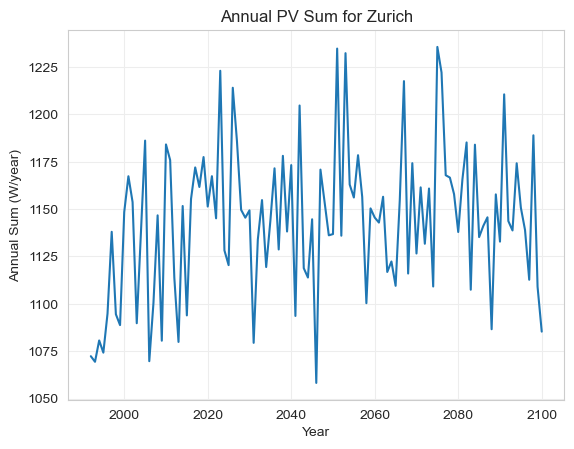

In [21]:
# Zurich coordinates
zurich_lat = 47.3769
zurich_lon = 8.5417

# Plot
annual_sum.sel(lat=zurich_lat, lon=zurich_lon, method="nearest").plot()
plt.title("Annual PV Sum for Zurich")
plt.ylabel("Annual Sum (W/year)")
plt.xlabel("Year")
plt.show()

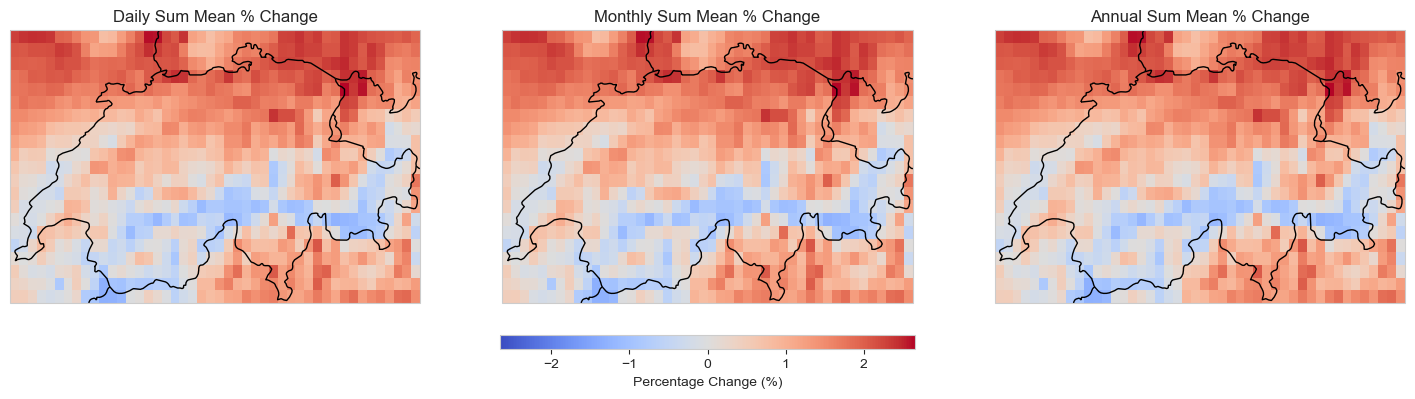

In [ ]:
# Plot with Mercator projection and canton borders, single horizontal colorbar
proj = ccrs.Mercator(central_longitude=8.0, min_latitude=45.8, max_latitude=47.9)
fig, axs = plt.subplots(
    1, 3, figsize=(18, 6), sharey=True, subplot_kw={"projection": proj}
)

vmin = min(
    pct_daily.min().compute(), pct_monthly.min().compute(), pct_annual.min().compute()
)
vmax = max(
    pct_daily.max().compute(), pct_monthly.max().compute(), pct_annual.max().compute()
)
abs_max = max(abs(vmin), abs(vmax))

im_list = []
for ax, data, title in zip(
    axs,
    [pct_daily, pct_monthly, pct_annual],
    [
        "Daily Sum Mean % Change",
        "Monthly Sum Mean % Change",
        "Annual Sum Mean % Change",
    ],
):
    im = data.plot(
        ax=ax,
        cmap="coolwarm",
        transform=ccrs.PlateCarree(),
        add_colorbar=False,
        vmin=-abs_max,
        vmax=abs_max,
    )
    im_list.append(im)
    ax.add_feature(
        cfeature.BORDERS, linestyle="-", edgecolor="black"
    )  # Add country borders
    ax.add_feature(cfeature.COASTLINE, edgecolor="black")  # Add coastlines
    ax.set_title(title)

cbar = fig.colorbar(
    im_list[0], ax=axs, orientation="horizontal", fraction=0.03, pad=0.07, aspect=30
)
cbar.set_label("Percentage Change (%)")
plt.show()

### Interannual variability

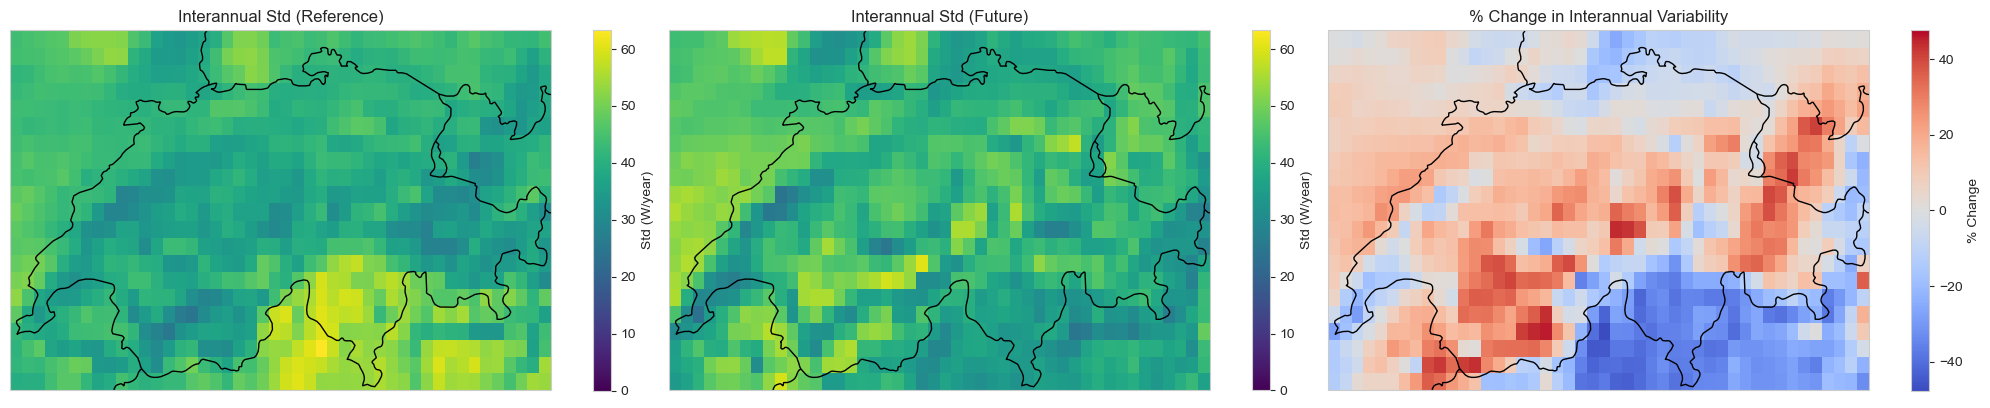

In [ ]:
# Interannual variability (standard deviation of annual sums)
interannual_std_ref = annual_sum.sel(time=reference_period).std(dim="time")
interannual_std_fut = annual_sum.sel(time=future_period).std(dim="time")

# Percentage change in interannual variability
pct_change_std = ((interannual_std_fut - interannual_std_ref) / interannual_std_ref) * 100

# Shared vmin/vmax for std plots
std_min = min(float(interannual_std_ref.min().compute()), float(interannual_std_fut.min().compute()))
std_max = max(float(interannual_std_ref.max().compute()), float(interannual_std_fut.max().compute()))

# Separate vmin/vmax for percentage change
pct_min = float(pct_change_std.min().compute())
pct_max = float(pct_change_std.max().compute())
pct_abs_max = max(abs(pct_min), abs(pct_max))

proj = ccrs.Mercator(central_longitude=8.0, min_latitude=45.8, max_latitude=47.9)
fig, axs = plt.subplots(1, 3, figsize=(20, 6), sharey=True, subplot_kw={"projection": proj})

# Reference std
im0 = interannual_std_ref.plot(
    ax=axs[0],
    cmap="viridis",
    vmin=0,
    vmax=std_max,
    transform=ccrs.PlateCarree(),
    cbar_kwargs={
        "label": "Std (W/year)",
        "orientation": "vertical",
        "fraction": 0.03,
        "pad": 0.07,
        "aspect": 20,
    },
)
axs[0].add_feature(cfeature.BORDERS, linestyle="-", edgecolor="black")
axs[0].add_feature(cfeature.COASTLINE, edgecolor="black")
axs[0].set_title("Interannual Std (Reference)")

# Future std
im1 = interannual_std_fut.plot(
    ax=axs[1],
    cmap="viridis",
    vmin=0,
    vmax=std_max,
    transform=ccrs.PlateCarree(),
    cbar_kwargs={
        "label": "Std (W/year)",
        "orientation": "vertical",
        "fraction": 0.03,
        "pad": 0.07,
        "aspect": 20,
    },
)
axs[1].add_feature(cfeature.BORDERS, linestyle="-", edgecolor="black")
axs[1].add_feature(cfeature.COASTLINE, edgecolor="black")
axs[1].set_title("Interannual Std (Future)")

# Percentage change
im2 = pct_change_std.plot(
    ax=axs[2],
    cmap="coolwarm",
    vmin=-pct_abs_max,
    vmax=pct_abs_max,
    transform=ccrs.PlateCarree(),
    cbar_kwargs={
        "label": "% Change",
        "orientation": "vertical",
        "fraction": 0.03,
        "pad": 0.07,
        "aspect": 20,
    },
)
axs[2].add_feature(cfeature.BORDERS, linestyle="-", edgecolor="black")
axs[2].add_feature(cfeature.COASTLINE, edgecolor="black")
axs[2].set_title("% Change in Interannual Variability")

plt.tight_layout()
plt.show()

# Europe

In [7]:
path_pv = (
    path_energy_europe
    / "pv"
    / f"{climate_model_chain}_{climate_scenario}"
    / f"pv_{climate_model_chain}_{climate_scenario}.zarr"
)

path_pv_agg = (
    path_energy_europe
    / "pv"
    / f"{climate_model_chain}_{climate_scenario}"
    / f"pv_agg_{climate_model_chain}_{climate_scenario}.nc"
)

ds_pv_rcp26 = xr.open_zarr(
    str(path_pv).replace(climate_scenario, "rcp26"), chunks="auto"
)
ds_pv_rcp85 = xr.open_zarr(
    str(path_pv).replace(climate_scenario, "rcp85"), chunks="auto"
)

ds_pv_agg_rcp26 = xr.open_dataset(str(path_pv_agg).replace(climate_scenario, "rcp26"))
ds_pv_agg_rcp85 = xr.open_dataset(str(path_pv_agg).replace(climate_scenario, "rcp85"))

In [7]:
path_pv = path_energy_europe / "pv"
path_pv_zarr = sorted(path_pv.glob("*/*.zarr"))
paths_pv_nc = sorted(path_pv.glob("*/pv_agg_*.nc"))

In [ ]:
ds_orog_cnrm = sel_extent(
    xr.open_dataset(
        sorted(
            (path_data_temporary / "cordex_processed").glob("CNRM*/regridded/fx/*.nc")
        )[0]
    ),
    EXTENT_BC,
)

In [ ]:
climate_scenario = "rcp26"
paths_wind = sorted(
    (
        path_energy_europe / "wind_power" / f"{climate_model_chain}_{climate_scenario}"
    ).glob(f"wind_power_agg_{climate_model_chain}_{climate_scenario}*.nc")
)

## Analysis

In [8]:
selected_var = "tilt_35_azimuth_S"
reference_period = slice("1991", "2020")
future_period = slice("2021", "2050")

### Entire grid

In [9]:
# Calculate the mean values for the future period
mean_future = (ds_pv_rcp26[selected_var]).sel(time=future_period).mean(dim="time")

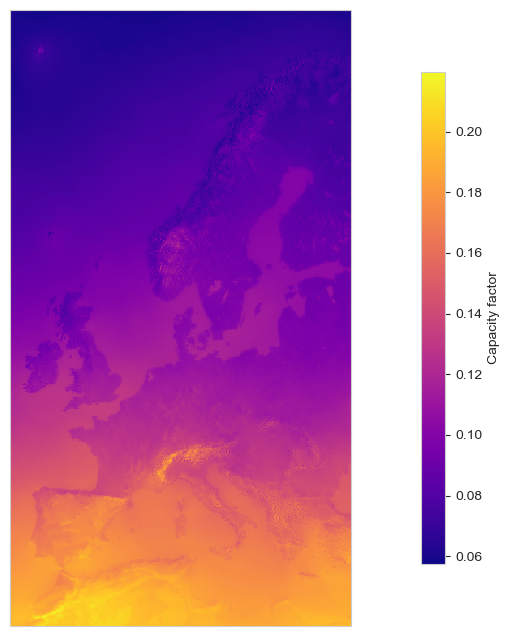

In [10]:
proj = ccrs.Mercator(central_longitude=10.0, min_latitude=30.0, max_latitude=75.0)
fig, axes = plt.subplots(figsize=(18, 8), subplot_kw={"projection": proj})
mean_future.plot(
    ax=axes,
    cmap="plasma",
    transform=ccrs.PlateCarree(),
    cbar_kwargs={
        "label": "Capacity factor",
        "shrink": 0.8,
        "orientation": "vertical",
        "pad": 0.05,
        "aspect": 20,
    },
)
plt.show()

### Country aggregates

In [ ]:
yearly_aggregated_future_rcp26 = (
    ds_pv_agg_rcp26.sel(time=future_period).resample(time="1YE").mean()
)

yearly_aggregated_future_rcp85 = (
    ds_pv_agg_rcp85.sel(time=future_period).resample(time="1YE").mean()
)

In [12]:
yearly_aggregated_future_rcp85

<xarray.Dataset> Size: 10kB
Dimensions:            (time: 30, country: 30)
Coordinates:
  * country            (country) <U22 3kB 'France' ... 'Bosnia and Herzegovina'
  * time               (time) datetime64[ns] 240B 2021-12-31 ... 2050-12-31
Data variables:
    tilt_35_azimuth_S  (time, country) float64 7kB 0.1504 0.1005 ... 0.1533

In [ ]:
# plot_yearly_mean_boxplot([yearly_aggregated_future_rcp26, yearly_aggregated_future_rcp85], ["RCP2.6, RCP8.5"], selected_var=selected_var, regions_to_plot=)

# Comparison with CESM

In [13]:
ds_cesm = xr.open_mfdataset(
    sorted(
        Path(
            "/net/xenon/climphys/lbloin/CESM2energy/output/bias_correction/A/SSP370/A/output_variables/"
        ).glob("PV*.nc")
    )
)

In [14]:
df_cesm_single_year = pd.read_csv(
    sorted(
        Path(
            "/net/xenon/climphys/lbloin/CESM2energy/output/bias_correction/A/SSP370/A/output_variables/"
        ).glob("PV*.csv")
    )[0],
)

In [15]:
list_files_cesm = sorted(
    Path(
        "/net/xenon/climphys/lbloin/CESM2energy/output/bias_correction/A/SSP370/A/output_variables/"
    ).glob("PV*.csv")
)
df_cesm = pd.concat(
    [
        pd.read_csv(file).rename({"country": f"country_{i}"}, axis=1)
        for i, file in enumerate(list_files_cesm)
    ],
    axis=1,
).drop(columns=[f"country_{i}" for i in range(len(list_files_cesm)) if i > 0])
df_cesm = df_cesm.rename({"country_0": "country"}, axis=1)
df_cesm = df_cesm.T
df_cesm.columns = df_cesm.iloc[0].tolist()
df_cesm = df_cesm[1:]
df_cesm.index = pd.to_datetime(df_cesm.index)
df_cesm.head()

,Albania,Austria,Bosnia and Herzegovina,Belgium,Bulgaria,Switzerland,Czech Republic,Germany,Denmark,Estonia,...,Netherlands,Norway,Poland,Portugal,Romania,Serbia,Sweden,Slovenia,Slovakia,United Kingdom
2080-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2080-01-01 02:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2080-01-01 03:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2080-01-01 04:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2080-01-01 05:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [16]:
# Group by month and calculate the mean over the entire period
df_cesm_monthly_mean = df_cesm.groupby(df_cesm.index.month).mean()
df_cesm_monthly_mean

,Albania,Austria,Bosnia and Herzegovina,Belgium,Bulgaria,Switzerland,Czech Republic,Germany,Denmark,Estonia,...,Netherlands,Norway,Poland,Portugal,Romania,Serbia,Sweden,Slovenia,Slovakia,United Kingdom
1,0.114172,0.10912,0.092058,0.060651,0.111025,0.116204,0.070047,0.072122,0.040944,0.029921,...,0.053875,0.026621,0.055139,0.119743,0.09209,0.099849,0.031469,0.094225,0.070755,0.04913
2,0.152575,0.138639,0.134412,0.082813,0.152054,0.1401,0.104026,0.099325,0.072887,0.06238,...,0.078617,0.067555,0.086503,0.157778,0.130565,0.146849,0.06841,0.129268,0.107097,0.073369
3,0.169202,0.156803,0.155557,0.117437,0.165247,0.16689,0.134149,0.131919,0.125573,0.123577,...,0.118043,0.128969,0.125575,0.185885,0.155135,0.15723,0.118681,0.153623,0.138094,0.115194
4,0.200886,0.177667,0.186909,0.159321,0.186307,0.187854,0.170095,0.164783,0.170001,0.171904,...,0.161865,0.168142,0.162974,0.206211,0.180948,0.185029,0.162022,0.173823,0.172714,0.154722
5,0.205453,0.183637,0.195847,0.178276,0.191246,0.190653,0.18208,0.18081,0.201545,0.201884,...,0.185068,0.182482,0.182555,0.208189,0.187149,0.191794,0.188718,0.181741,0.184551,0.180341
6,0.206333,0.186234,0.194832,0.183922,0.192474,0.19906,0.183225,0.185666,0.207369,0.211764,...,0.18761,0.183799,0.184472,0.212323,0.186612,0.189346,0.197221,0.181607,0.183998,0.185759
7,0.215318,0.192929,0.205356,0.185227,0.203711,0.212361,0.183371,0.185444,0.192553,0.197343,...,0.178515,0.161709,0.183058,0.218596,0.196169,0.202205,0.185113,0.189347,0.187995,0.169271
8,0.211683,0.187118,0.200646,0.171766,0.201107,0.20821,0.17622,0.175369,0.169,0.164796,...,0.16048,0.128703,0.170278,0.21493,0.191852,0.200693,0.154566,0.18339,0.181273,0.149786
9,0.202796,0.181297,0.190178,0.14932,0.200517,0.1932,0.16224,0.158329,0.137839,0.140247,...,0.139459,0.105621,0.154274,0.205244,0.186502,0.19808,0.13172,0.17552,0.168941,0.128635
10,0.172146,0.150912,0.155275,0.106977,0.166489,0.157313,0.126884,0.121227,0.094387,0.086204,...,0.099507,0.075758,0.112161,0.176802,0.151548,0.166023,0.089195,0.140566,0.132301,0.097729


In [17]:
df_pv_agg_rcp26 = (
    ds_pv_agg_rcp26["tilt_35_azimuth_S"]
    .to_dataframe()
    .reset_index()
    .pivot(index="time", columns="country", values="tilt_35_azimuth_S")
)
df_pv_agg_rcp26_monthly_mean = df_pv_agg_rcp26.groupby(
    df_pv_agg_rcp26.index.month
).mean()

df_pv_agg_rcp85 = (
    ds_pv_agg_rcp85["tilt_35_azimuth_S"]
    .to_dataframe()
    .reset_index()
    .pivot(index="time", columns="country", values="tilt_35_azimuth_S")
)
df_pv_agg_rcp85_monthly_mean = df_pv_agg_rcp85.groupby(
    df_pv_agg_rcp85.index.month
).mean()

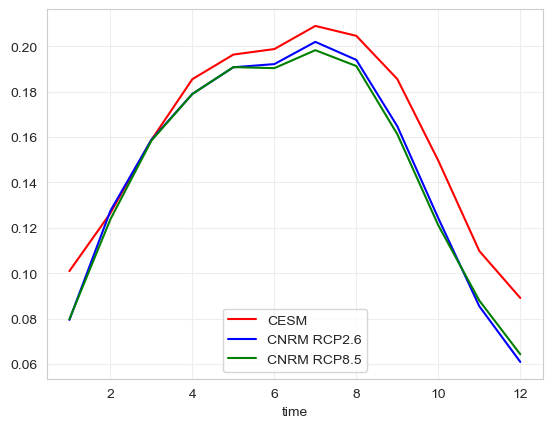

In [18]:
df_cesm_monthly_mean["France"].plot(color="red", label="CESM")
df_pv_agg_rcp26_monthly_mean["France"].plot(color="blue", label="CNRM RCP2.6")
df_pv_agg_rcp85_monthly_mean["France"].plot(color="green", label="CNRM RCP8.5")
plt.legend()

ValueError: Dataset.plot cannot be called directly. Use an explicit plot method, e.g. ds.plot.scatter(...)

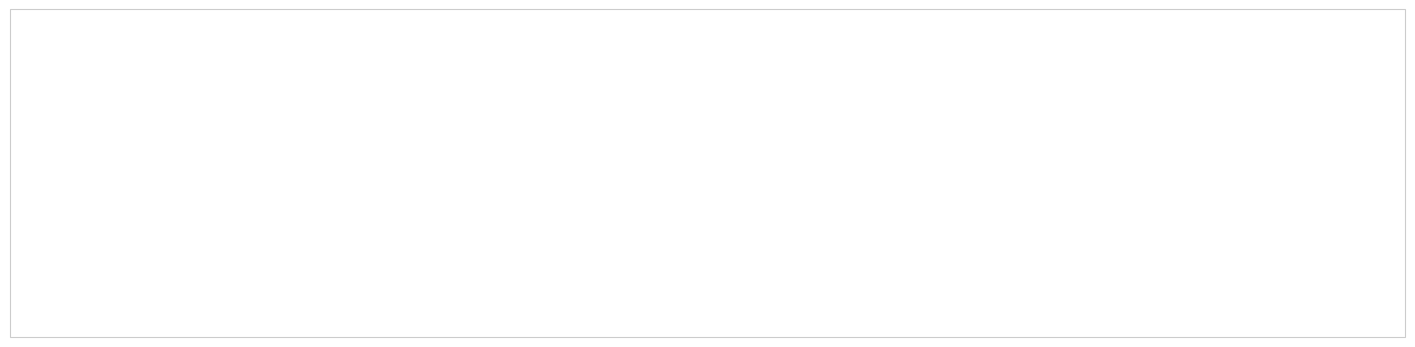

In [19]:
# Calculate the mean values for the future period
mean_cesm = ds_cesm.sel(time=future_period).mean(dim="time")
proj = ccrs.Mercator(central_longitude=10.0, min_latitude=30.0, max_latitude=75.0)
fig, axes = plt.subplots(figsize=(18, 8), subplot_kw={"projection": proj})
mean_cesm.plot(
    ax=axes,
    cmap="plasma",
    transform=ccrs.PlateCarree(),
    cbar_kwargs={
        "label": "Capacity factor",
        "shrink": 0.8,
        "orientation": "vertical",
        "pad": 0.05,
        "aspect": 20,
    },
)
plt.show()